In [11]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
from ydata_profiling import ProfileReport
%matplotlib inline

In [25]:
# Load dataset
df = pd.read_csv(r"C:/Users/World/Downloads/Compressed/seattle-weather.csv")  # replace with your path

# Generate Profile Report
profile = ProfileReport(df, title="CLV Data Profiling Report", explorative=True)

# Show report in notebook
profile.to_notebook_iframe()

# (Optional) Save to HTML for offline viewing
profile.to_file("clv_data_profile_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 96.47it/s]%|                                                                                            | 0/6 [00:00<?, ?it/s]%|                                                                                            | 0/6 [00:00<?, ?it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
df.head()


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [27]:
df['date'] = pd.to_datetime(df['date'])
df['date']

0      2012-01-01
1      2012-01-02
2      2012-01-03
3      2012-01-04
4      2012-01-05
          ...    
1456   2015-12-27
1457   2015-12-28
1458   2015-12-29
1459   2015-12-30
1460   2015-12-31
Name: date, Length: 1461, dtype: datetime64[ns]

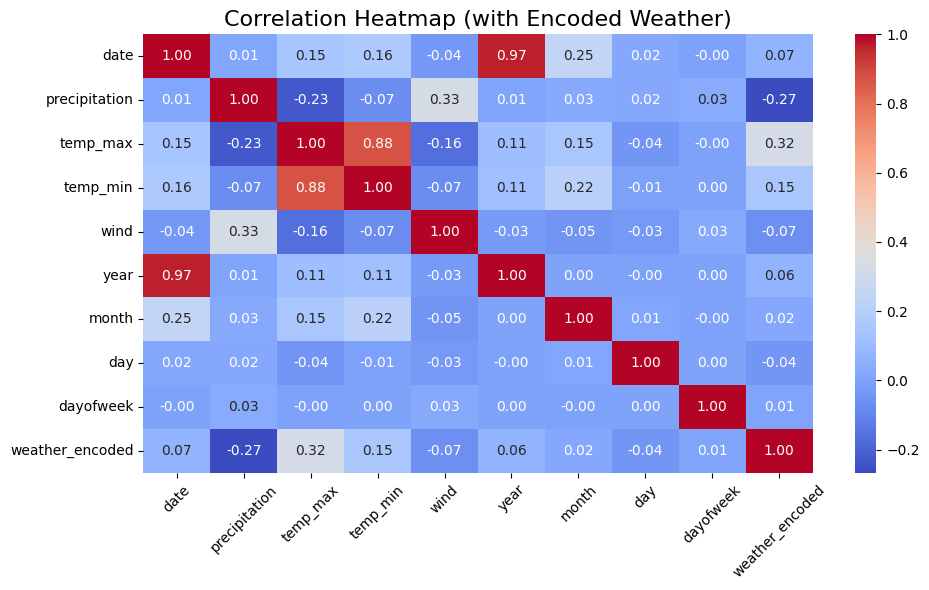

In [79]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
# Encode weather column to numeric
df['weather_encoded'] = le.fit_transform(df_encoded['weather'])

# Select numeric columns again (now weather is numeric)
numeric_df = df.select_dtypes(include=[np.number,'datetime'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap (with Encoded Weather)", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [80]:
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import f1_score,r2_score,mean_absolute_error,mean_squared_error,accuracy_score, classification_report, confusion_matrix


In [81]:
# Extract numeric features from date
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['dayofweek'] = df['date'].dt.dayofweek

# Drop original date column
X_linear = df.drop(columns=['date', 'weather','weather_encoded'])  # assuming 'weather' is your target

# Define target (example)
y_linear = df['weather_encoded']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_linear, y_linear, test_size=0.2, random_state=42)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled,X_test_scaled,y_train

(array([[-0.45562998, -1.48337156, -2.29332143, ...,  1.60943041,
         -1.54960835, -1.00117885],
        [ 2.27136019, -0.34592487,  0.34906529, ...,  0.73441968,
          1.62354245, -1.50069909],
        [ 2.31558165, -0.57889588, -0.43163988, ..., -1.01560178,
         -0.64299383, -1.50069909],
        ...,
        [-0.38192754, -0.11295386, -0.21144098, ..., -0.43226129,
         -0.64299383,  0.99690213],
        [-0.45562998, -1.48337156, -1.85292364, ...,  1.60943041,
          1.62354245, -0.5016586 ],
        [-0.45562998, -1.26410473, -0.99214615, ..., -1.59894227,
          1.73686926,  0.99690213]]),
 array([[-0.45562998,  1.02449282,  0.56926418, ..., -0.14059105,
         -0.52966702, -0.5016586 ],
        [ 0.39931829, -1.18187966, -0.43163988, ..., -1.59894227,
         -0.64299383,  0.99690213],
        [-0.45562998, -0.96261283, -0.77194726, ..., -1.30727202,
          0.15029387,  1.49642238],
        ...,
        [-0.45562998, -0.19517892, -0.31153139, ...,  

In [82]:
LR=LinearRegression()
model=LR.fit(X_train_scaled,y_train)
model

LinearRegression()

In [83]:
y_pred = model.predict(X_test_scaled)
y_pred

array([3.32422996, 1.90281645, 2.48360892, 3.47065099, 2.68018058,
       1.90553101, 3.1727479 , 3.23519199, 1.9610981 , 3.56479821,
       3.12489525, 3.7900635 , 2.32564411, 3.13650246, 2.64364723,
       2.27471635, 2.8182316 , 2.12129198, 3.03488479, 3.48082849,
       2.70355543, 3.01137801, 2.52850241, 2.61465687, 3.4199491 ,
       1.75120584, 2.83397028, 3.20838133, 3.1499788 , 3.33203308,
       2.62248865, 3.3114448 , 2.7222511 , 2.67074479, 3.22540312,
       2.52275283, 2.23663056, 1.74323805, 2.48586132, 3.55388771,
       2.16277782, 3.10023186, 2.52322479, 3.50895893, 2.36622595,
       2.01972231, 2.66680804, 2.43616276, 3.15817629, 3.51306451,
       2.89233899, 2.69254931, 3.93471951, 2.45912035, 3.0248627 ,
       2.14068989, 2.94281251, 3.28694176, 2.14821504, 3.17568386,
       1.9521514 , 3.22954696, 2.51877808, 2.51952379, 3.16899076,
       2.94835689, 2.07902645, 3.82958884, 1.82163083, 2.32676248,
       2.34746156, 3.01183372, 2.92012367, 2.76556625, 2.72441

In [84]:
# R² Score
r2 = r2_score(y_test, y_pred)

# MAE, MSE, RMSE
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R² Score: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

R² Score: 0.2434
MAE: 0.8343
MSE: 1.0771
RMSE: 1.0378



**Use LogisticRegression model for more accuracy due to categorical value**


Accuracy: 0.7918

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       1.00      0.04      0.08        25
           2       0.86      0.88      0.87       120
           3       1.00      0.12      0.22         8
           4       0.74      0.95      0.83       131

    accuracy                           0.79       293
   macro avg       0.72      0.40      0.40       293
weighted avg       0.80      0.79      0.74       293



C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


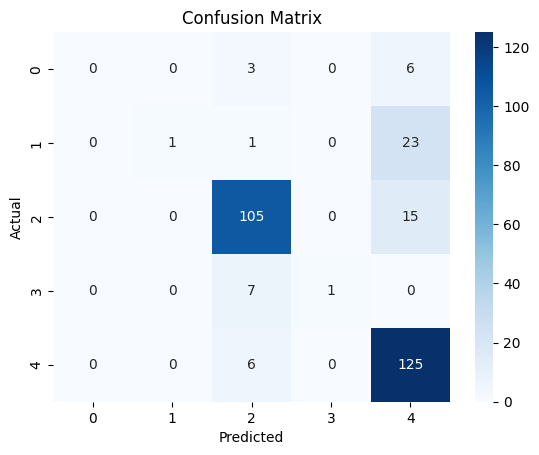

In [85]:
log_reg = LogisticRegression(max_iter=500)
log_reg.fit(X_train_scaled, y_train)

# Predict
y_pred = log_reg.predict(X_test_scaled)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


Best Parameters: {'C': 100, 'class_weight': None, 'solver': 'lbfgs'}
Best Accuracy on Train CV: 0.8459264150251273
Test Accuracy: 0.8362

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       1.00      0.04      0.08        25
           2       0.94      0.93      0.94       120
           3       1.00      0.12      0.22         8
           4       0.76      1.00      0.86       131

    accuracy                           0.84       293
   macro avg       0.74      0.42      0.42       293
weighted avg       0.84      0.84      0.78       293



C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


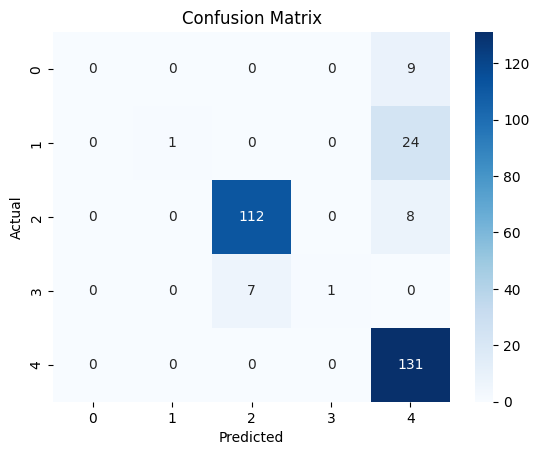

In [87]:


param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
    'solver': ['liblinear', 'lbfgs', 'saga'],
    'class_weight': [None, 'balanced']
}

log_reg = LogisticRegression(max_iter=1000)
grid = GridSearchCV(log_reg, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Accuracy on Train CV:", grid.best_score_)

# Evaluate on Test Data
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test_scaled)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


Random Forest Accuracy: 0.8498293515358362
              precision    recall  f1-score   support

           0       1.00      0.11      0.20         9
           1       0.86      0.24      0.38        25
           2       0.94      0.93      0.93       120
           3       0.50      0.12      0.20         8
           4       0.79      0.99      0.88       131

    accuracy                           0.85       293
   macro avg       0.82      0.48      0.52       293
weighted avg       0.86      0.85      0.82       293



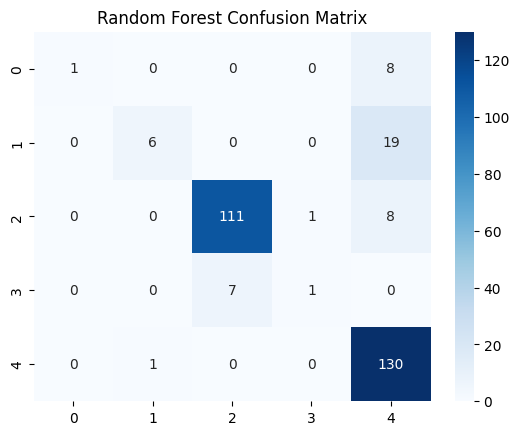

In [89]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()


In [ ]:
### import pandas as pd

# === Show all possible weather classes ===
print("Available Weather Classes:", list(le.classes_))

# === Interactive Prediction Console ===
while True:
    print("\n--- Weather Prediction Console ---")
    try:
        # Take user input
        precipitation = float(input("Enter precipitation (e.g., 1.0): "))
        temp_max = float(input("Enter max temp (°C): "))
        temp_min = float(input("Enter min temp (°C): "))
        wind = float(input("Enter wind speed: "))
        year = int(input("Enter year (e.g., 2015): "))
        month = int(input("Enter month (1-12): "))
        day = int(input("Enter day (1-31): "))
        dayofweek = int(input("Enter dayofweek (0=Mon ... 6=Sun): "))

        # Build dataframe
        new_data = pd.DataFrame([{
            'precipitation': precipitation,
            'temp_max': temp_max,
            'temp_min': temp_min,
            'wind': wind,
            'year': year,
            'month': month,
            'day': day,
            'dayofweek': dayofweek
        }])

        # Predict
        prediction = rf.predict(new_data)
        decoded_prediction = le.inverse_transform(prediction)

        print(f"\nPredicted Weather: {decoded_prediction[0]} (Class Index: {prediction[0]})")

    except Exception as e:
        print(f"Error: {e}")

    # Option to continue or exit
    cont = input("\nDo you want to predict again? (y/n): ").strip().lower()
    if cont != 'y':
        print("Exiting Prediction Console. Goodbye!")
        break


Available Weather Classes: ['drizzle', 'fog', 'rain', 'snow', 'sun']

--- Weather Prediction Console ---


Enter precipitation (e.g., 1.0):  1
Enter max temp (°C):  10
in temp (°C):  03

Enter wind speed:  1
year (e.g., 2015):  2011
Enter month (1-12):  311

day (1-31):  15311


Enter dayofweek (0=Mon ... 6=Sun):  2



Predicted Weather: rain (Class Index: 2)



Do you want to predict again? (y/n):  y



--- Weather Prediction Console ---


Enter precipitation (e.g., 1.0):  0
Enter max temp (°C):  10
in temp (°C):  2.8
Enter wind speed:  2
year (e.g., 2015):  2012
Enter month (1-12):  812

day (1-31):  1 812


Enter dayofweek (0=Mon ... 6=Sun):  0



Predicted Weather: sun (Class Index: 4)



Do you want to predict again? (y/n):  y



--- Weather Prediction Console ---


Enter precipitation (e.g., 1.0):  0.3
Enter max temp (°C):  45
in temp (°C):  21

Enter wind speed:  2.5
year (e.g., 2015):  2015
Enter month (1-12):  515

day (1-31):  19515


Enter dayofweek (0=Mon ... 6=Sun):  5



Predicted Weather: rain (Class Index: 2)



Logistic Regression Accuracy: 0.5972696245733788
              precision    recall  f1-score   support

           0       0.15      1.00      0.26         9
           1       0.29      0.64      0.40        25
           2       0.96      0.72      0.82       120
           3       0.36      1.00      0.53         8
           4       0.86      0.43      0.57       131

    accuracy                           0.60       293
   macro avg       0.52      0.76      0.52       293
weighted avg       0.82      0.60      0.65       293



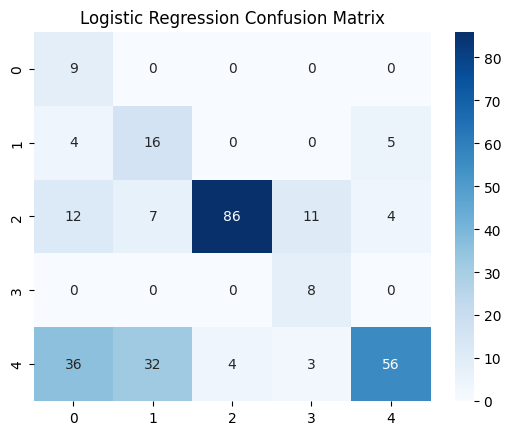


Random Forest Accuracy: 0.8498293515358362
              precision    recall  f1-score   support

           0       1.00      0.11      0.20         9
           1       0.86      0.24      0.38        25
           2       0.94      0.93      0.93       120
           3       0.50      0.12      0.20         8
           4       0.79      0.99      0.88       131

    accuracy                           0.85       293
   macro avg       0.82      0.48      0.52       293
weighted avg       0.86      0.85      0.82       293



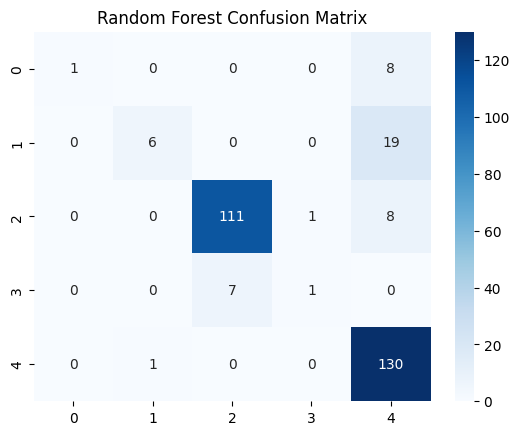


SVC Accuracy: 0.5938566552901023
              precision    recall  f1-score   support

           0       0.11      0.56      0.18         9
           1       0.30      0.64      0.41        25
           2       0.89      0.61      0.72       120
           3       0.33      0.50      0.40         8
           4       0.77      0.58      0.66       131

    accuracy                           0.59       293
   macro avg       0.48      0.58      0.47       293
weighted avg       0.75      0.59      0.64       293



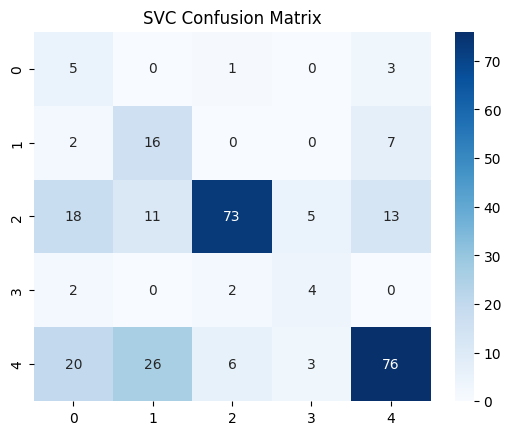

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)
print("\nLogistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))

# Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("\nRandom Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

# Support Vector Classifier (optional)
svc = SVC(class_weight='balanced', probability=True)
svc.fit(X_train_scaled, y_train)
y_pred_svc = svc.predict(X_test_scaled)
print("\nSVC Accuracy:", accuracy_score(y_test, y_pred_svc))
print(classification_report(y_test, y_pred_svc))

sns.heatmap(confusion_matrix(y_test, y_pred_svc), annot=True, fmt="d", cmap="Blues")
plt.title("SVC Confusion Matrix")
plt.show()


In [72]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced']
}

rf = RandomForestClassifier(random_state=42)
search = RandomizedSearchCV(rf, param_grid, cv=5, scoring='f1_weighted', n_iter=20, n_jobs=-1)
search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
best_rf = search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)

print("\nBest Random Forest Accuracy:", accuracy_score(y_test, y_pred_best_rf))
print(classification_report(y_test, y_pred_best_rf))


Best Parameters: {'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'class_weight': 'balanced'}

Best Random Forest Accuracy: 0.8293515358361775
              precision    recall  f1-score   support

           0       0.40      0.44      0.42         9
           1       0.45      0.36      0.40        25
           2       0.96      0.92      0.94       120
           3       0.67      0.50      0.57         8
           4       0.81      0.89      0.85       131

    accuracy                           0.83       293
   macro avg       0.66      0.62      0.64       293
weighted avg       0.83      0.83      0.83       293



NotFittedError: This RandomForestClassifier instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.